In [1]:
import sys
import os

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(REPO_ROOT, 'code'))

import numpy as np
import pandas as pd

from scunit import ScUnit
from analysis_tools import *


Data is loaded by passing a path to the ScUnit class. Optionally, a minimum number of mutations per cell can be specified to filter out low-coverage cells.

In [5]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/funnell2022single-OV2295.csv'))
Y = ScUnit(FILEPATH, min_mutations=50)

Loaded 1084 cells.
Mutations per cell:
	min:  65
	mean: 2009
	max:  4111


In [6]:
Y.df_mutations.iloc[:5, :8]

,A[C>A]A,A[C>A]C,A[C>A]G,A[C>A]T,A[C>G]A,A[C>G]C,A[C>G]G,A[C>G]T
cell_id,,,,,,,,
SA1090-A96213A-R20-C11,18,5,3,10,12,5,9,8
SA1090-A96213A-R20-C18,13,9,3,15,19,10,7,15
SA1090-A96213A-R20-C19,21,13,6,11,19,8,7,16
SA1090-A96213A-R20-C22,13,11,3,16,15,16,7,15
SA1090-A96213A-R20-C23,14,12,2,17,18,15,9,19


In [7]:
Y.df_contexts.iloc[:5, :8]

,ACA,ACC,ACG,ACT,ATA,ATC,ATG,ATT
cell_id,,,,,,,,
SA1090-A96213A-R20-C11,45,15,23,26,21,9,18,28
SA1090-A96213A-R20-C18,48,23,36,40,19,18,35,31
SA1090-A96213A-R20-C19,57,31,25,42,34,24,44,44
SA1090-A96213A-R20-C22,58,36,26,48,27,24,42,42
SA1090-A96213A-R20-C23,58,35,35,54,28,21,40,40


In [8]:
Y.df_substitutions.head()

,C>A,C>G,C>T,T>A,T>C,T>G
cell_id,,,,,,
SA1090-A96213A-R20-C11,121,120,162,101,159,72
SA1090-A96213A-R20-C18,172,165,211,126,209,109
SA1090-A96213A-R20-C19,200,170,239,149,265,141
SA1090-A96213A-R20-C22,193,184,256,176,228,124
SA1090-A96213A-R20-C23,199,196,246,150,250,137


In [9]:
sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a']


In [10]:
COSMIC_PATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'))
cosmic = pd.read_csv(COSMIC_PATH, sep = '\t').set_index('Type').T

In [11]:
Y.deconv(signatures=cosmic.loc[sigs].T)

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
cell_id,,,,,,,,
SA1090-A96213A-R20-C11,0.026534,0.018782,0.578423,0.206274,0.068101,0.085080,0.009050,0.007755
SA1090-A96213A-R20-C18,0.057525,0.017553,0.662469,0.098452,0.063492,0.078183,0.016602,0.005725
SA1090-A96213A-R20-C19,0.024013,0.007739,0.568307,0.233761,0.056904,0.094489,0.003129,0.011658
SA1090-A96213A-R20-C22,0.035249,0.014641,0.589706,0.201750,0.079695,0.073398,0.005561,0.000000
SA1090-A96213A-R20-C23,0.045787,0.012353,0.709263,0.128288,0.024225,0.064344,0.006804,0.008936
...,...,...,...,...,...,...,...,...
SA922-A90554B-R35-C59,0.025378,0.020397,0.798372,0.017383,0.000000,0.134261,0.002408,0.001801
SA922-A90554B-R35-C60,0.020446,0.023775,0.704045,0.059606,0.041178,0.132145,0.018805,0.000000
SA922-A90554B-R35-C61,0.026087,0.020244,0.749590,0.019979,0.021425,0.136938,0.018980,0.006758


In [12]:
labels = Y.umap().hdbscan().get_labels()
Y.deconv(signatures=cosmic.loc[sigs].T, aggregate_by=labels)

Silhouette: 0.9410
DBCV: 0.9641


,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
0,0.020951,0.007820,0.785402,0.035166,0.057994,0.085458,0.000000,0.007208
1,0.028792,0.015942,0.610719,0.177265,0.071077,0.077596,0.010722,0.007886
2,0.022661,0.019146,0.716451,0.062004,0.034382,0.129896,0.008903,0.006557


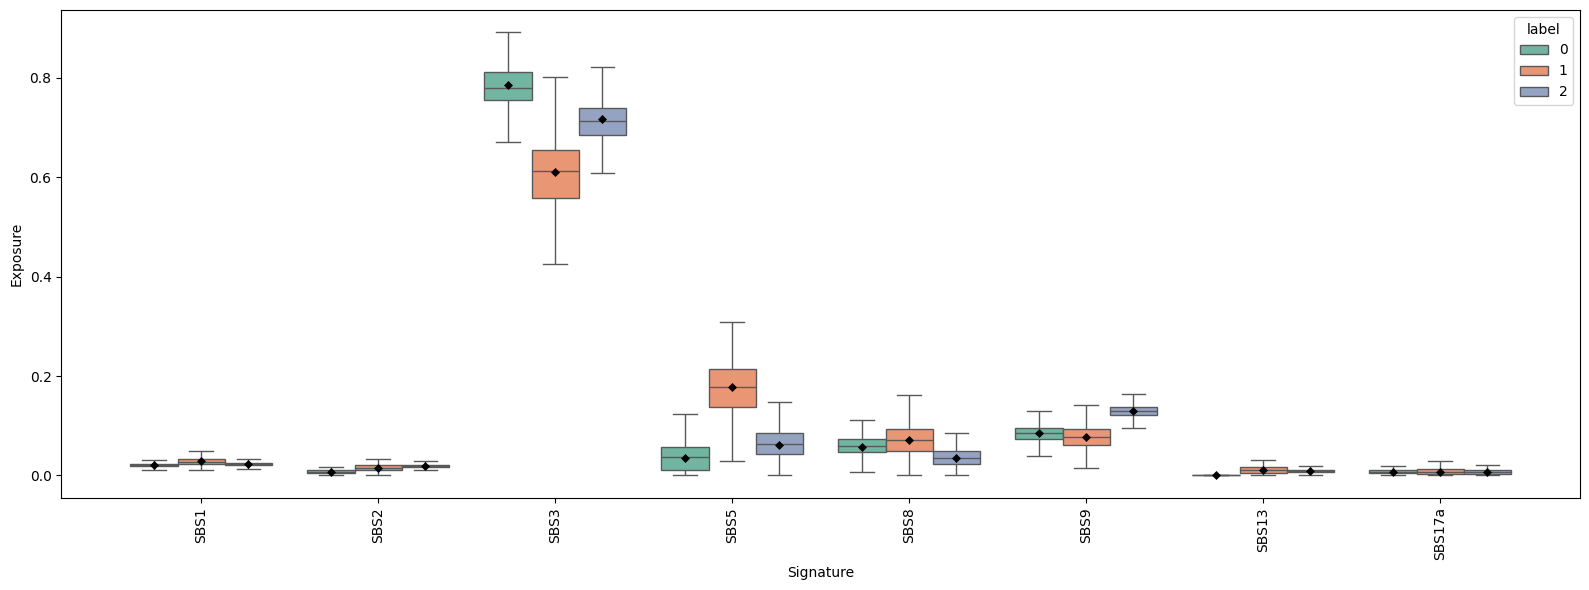

In [13]:
Y.umap().hdbscan().plot_exposures(cosmic.loc[sigs].T)

In [14]:
cosmic_contexts = cosmic.rename(columns={col: col[0] + col[2] + col[-1] for col in cosmic.columns}).groupby(level=0, axis=1).sum()
cosmic_substitutions = cosmic.rename(columns={col: col[2:5] for col in cosmic.columns}).groupby(level=0, axis=1).sum()

dmg_sig = pd.read_csv('../../data/damuta/damage_signatures.csv', index_col=0).sort_index(axis=1)
misr_sig = pd.read_csv('../../data/damuta/misrepair_signatures.csv', index_col=0).sort_index(axis=1)

In [15]:
Y.deconv(signatures=misr_sig.T)

,M1,M2,M3,M4,M5,M6
cell_id,,,,,,
SA1090-A96213A-R20-C11,0.0,0.140547,0.182657,0.427290,0.177223,0.072282
SA1090-A96213A-R20-C18,0.0,0.179016,0.182110,0.432148,0.162662,0.044064
SA1090-A96213A-R20-C19,0.0,0.193939,0.210278,0.401067,0.167972,0.026744
SA1090-A96213A-R20-C22,0.0,0.144616,0.118792,0.416839,0.181358,0.138395
SA1090-A96213A-R20-C23,0.0,0.187925,0.181481,0.440360,0.152190,0.038044
...,...,...,...,...,...,...
SA922-A90554B-R35-C59,0.0,0.269690,0.092631,0.454146,0.084615,0.098918
SA922-A90554B-R35-C60,0.0,0.242171,0.087815,0.470860,0.105447,0.093707
SA922-A90554B-R35-C61,0.0,0.238858,0.100284,0.479732,0.098669,0.082457


In [16]:
Y.deconv(signatures=cosmic_substitutions.loc[sigs].T)

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
cell_id,,,,,,,,
SA1090-A96213A-R20-C11,0.000000,0.097430,0.000000,0.271607,0.218372,0.175721,0.147906,0.088963
SA1090-A96213A-R20-C18,0.000000,0.023726,0.000000,0.498692,0.184756,0.166377,0.126449,0.000000
SA1090-A96213A-R20-C19,0.000000,0.003091,0.000000,0.538930,0.175020,0.187748,0.095212,0.000000
SA1090-A96213A-R20-C22,0.084391,0.000000,0.751508,0.000000,0.049809,0.073223,0.000000,0.041068
SA1090-A96213A-R20-C23,0.000000,0.021573,0.000000,0.487688,0.176165,0.187661,0.126913,0.000000
...,...,...,...,...,...,...,...,...
SA922-A90554B-R35-C59,0.000000,0.092117,0.000000,0.210873,0.188327,0.342835,0.165848,0.000000
SA922-A90554B-R35-C60,0.000000,0.081952,0.000000,0.240506,0.199348,0.306161,0.172034,0.000000
SA922-A90554B-R35-C61,0.000000,0.078733,0.000000,0.240493,0.186430,0.315263,0.169649,0.009432


In [17]:
Y.umap().hdbscan().summary()

cluster_label
0    389
1    390
2    305
Name: count, dtype: int64

In [18]:
Y.passthrough().hdbscan(min_cluster_size=10, min_samples=1).summary()

Silhouette: 0.2492
DBCV: 0.0080


cluster_label
-1    465
 0     19
 1     11
 2     19
 3     46
 4     24
 5     11
 6     16
 7     41
 8    412
 9     20
Name: count, dtype: int64

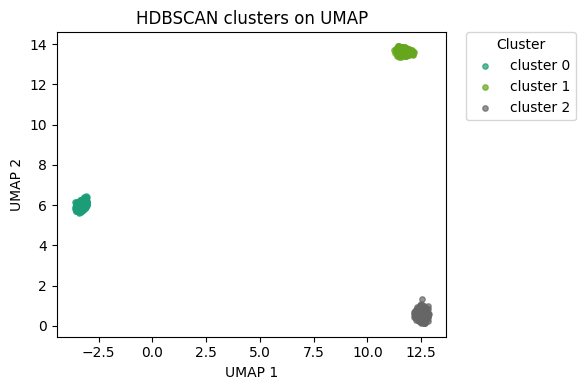

In [19]:
Y.umap().hdbscan().plot_embedding()

In [37]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/funnell2022single-SA1292.csv'))
Y = ScUnit(FILEPATH, min_mutations=50)

Loaded 404 cells.
Mutations per cell:
	min:  130
	mean: 349
	max:  956


Silhouette: 0.2342
DBCV: 0.2281


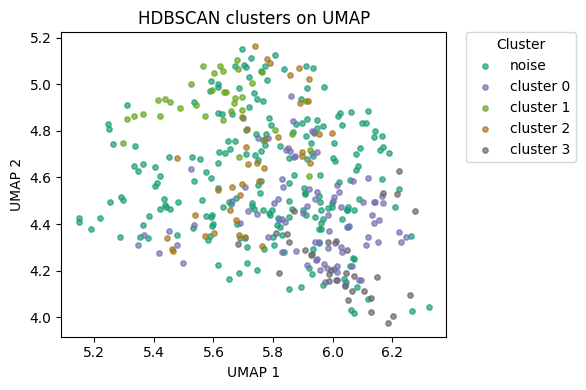

In [38]:
Y.umap().hdbscan().plot_embedding()

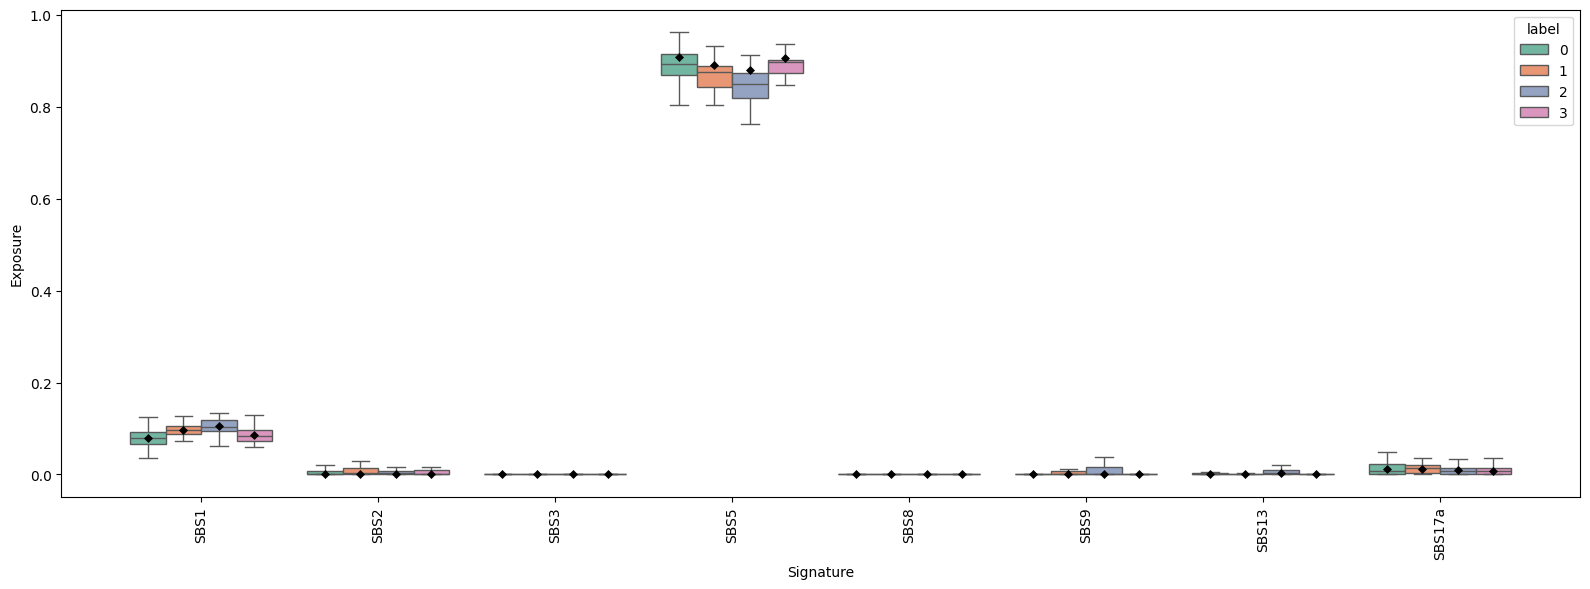

In [39]:
Y.umap().hdbscan().plot_exposures(cosmic.loc[sigs].T)

In [40]:
dmg_sig = pd.read_csv('../../data/damuta/damage_signatures.csv', index_col=0).sort_index(axis=1)
misr_sig = pd.read_csv('../../data/damuta/misrepair_signatures.csv', index_col=0).sort_index(axis=1)

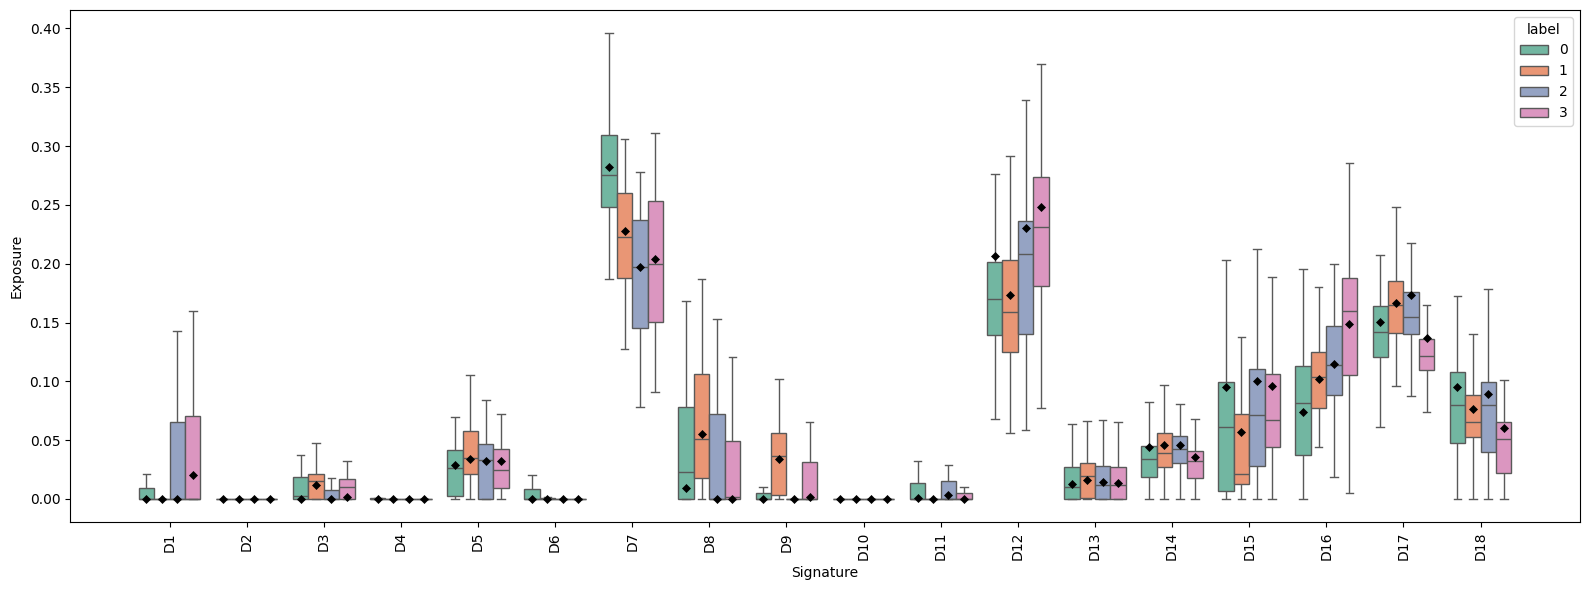

In [41]:
Y.umap().hdbscan().plot_exposures(signatures=dmg_sig.T)

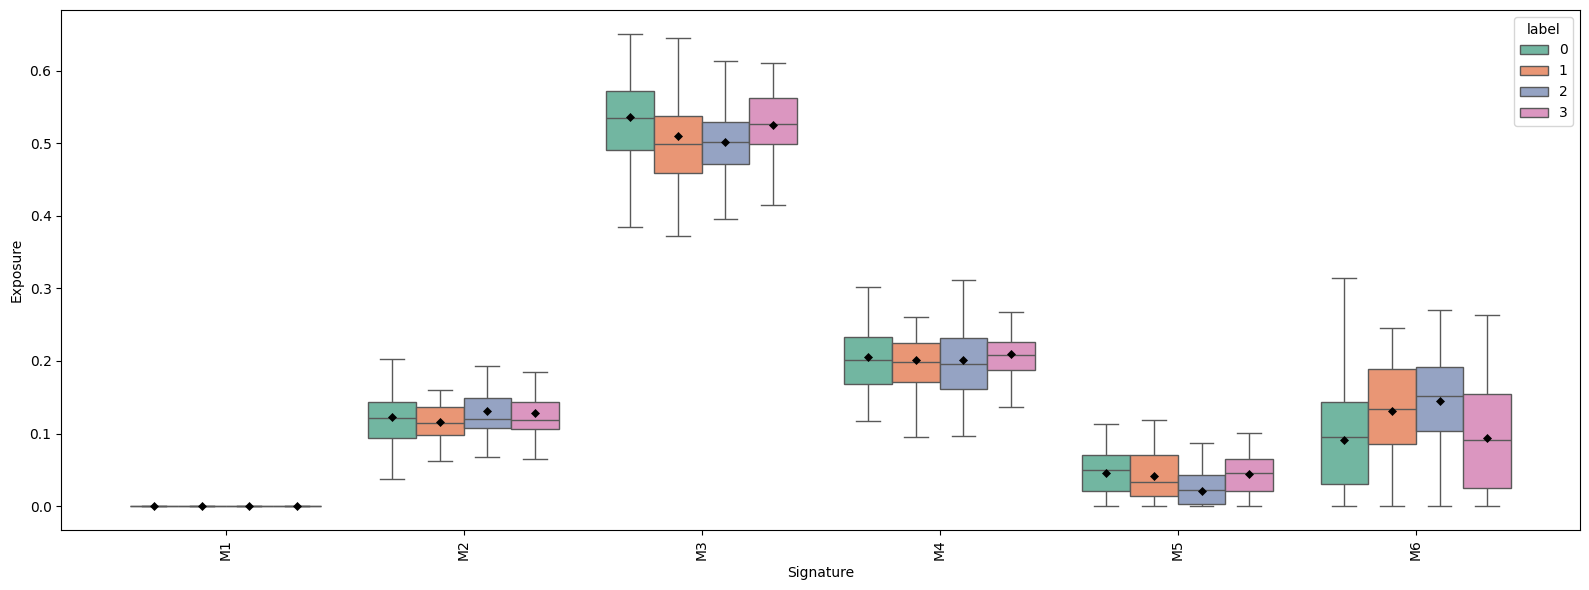

In [42]:
Y.umap().hdbscan().plot_exposures(signatures=misr_sig.T)